In [18]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, accuracy_score
from yellowbrick.classifier import ConfusionMatrix

In [19]:
credito = pd.read_csv('Credit.csv')
credito.shape

(1000, 21)

In [20]:
credito.head()

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,<0,6,'critical/other existing credit',radio/tv,1169,'no known savings',>=7,4,'male single',none,...,'real estate',67,none,own,2,skilled,1,yes,yes,good
1,0<=X<200,48,'existing paid',radio/tv,5951,<100,1<=X<4,2,'female div/dep/mar',none,...,'real estate',22,none,own,1,skilled,1,none,yes,bad
2,'no checking',12,'critical/other existing credit',education,2096,<100,4<=X<7,2,'male single',none,...,'real estate',49,none,own,1,'unskilled resident',2,none,yes,good
3,<0,42,'existing paid',furniture/equipment,7882,<100,4<=X<7,2,'male single',guarantor,...,'life insurance',45,none,'for free',1,skilled,2,none,yes,good
4,<0,24,'delayed previously','new car',4870,<100,1<=X<4,3,'male single',none,...,'no known property',53,none,'for free',2,skilled,2,none,yes,bad


In [21]:
previsores = credito.iloc[:,0:20].values
classe = credito.iloc[:,20].values

In [22]:
#Transformando atributos categoricos em atributos numericos, passando indice
#de cada coluna categorica. Se precisa criar um objeto pra cada atributo categorico,
#pois na sequencia sera executado o processo de encoding novamente pra registro de teste
#se forem utilizados objetos diferentes, o numero atribuido a cada valor podera ser
#diferente, o que deixara o teste inconsistente
labelencoder1 = LabelEncoder()
previsores[:,0] = labelencoder1.fit_transform(previsores[:,0])

labelencoder2 = LabelEncoder()
previsores[:,2] = labelencoder2.fit_transform(previsores[:,2])

labelencoder3 = LabelEncoder()
previsores[:,3] = labelencoder3.fit_transform(previsores[:,3])

labelencoder4 = LabelEncoder()
previsores[:,5] = labelencoder4.fit_transform(previsores[:,5])

labelencoder5 = LabelEncoder()
previsores[:,6] = labelencoder5.fit_transform(previsores[:,6])

labelencoder6 = LabelEncoder()
previsores[:,8] = labelencoder6.fit_transform(previsores[:,8])

labelencoder7 = LabelEncoder()
previsores[:,9] = labelencoder7.fit_transform(previsores[:,9])

labelencoder8 = LabelEncoder()
previsores[:,11] = labelencoder8.fit_transform(previsores[:,11])

labelencoder9 = LabelEncoder()
previsores[:,13] = labelencoder9.fit_transform(previsores[:,13])

labelencoder10 = LabelEncoder()
previsores[:,14] = labelencoder10.fit_transform(previsores[:,14])

labelencoder11 = LabelEncoder()
previsores[:,16] = labelencoder11.fit_transform(previsores[:,16])

labelencoder12 = LabelEncoder()
previsores[:,18] = labelencoder12.fit_transform(previsores[:,18])

labelencoder13 = LabelEncoder()
previsores[:,19] = labelencoder13.fit_transform(previsores[:,19])

In [23]:
#Divisao da base de dados entre treinamento e teste (30%teste e 70% treino)
X_treinamento, X_teste, y_treinamento, y_teste = train_test_split(previsores,
                                                                 classe,
                                                                 test_size = 0.3,
                                                                 random_state = 0)
X_teste

array([[2, 36, 3, ..., 1, 1, 1],
       [0, 9, 3, ..., 2, 0, 0],
       [0, 18, 3, ..., 1, 1, 1],
       ...,
       [0, 24, 1, ..., 1, 0, 1],
       [1, 27, 4, ..., 1, 1, 1],
       [1, 12, 3, ..., 1, 0, 1]], shape=(300, 20), dtype=object)

In [24]:
#Criacao e treinemento do modelo
naive_bayes = GaussianNB()
naive_bayes.fit(X_treinamento, y_treinamento)

,priors,None
,var_smoothing,1e-09


In [25]:
#Previsoes utilizando os registros de teste
previsoes = naive_bayes.predict(X_teste)

In [26]:
#Gerando a matriz de confusao e calculo da taxa de acerto e erro
confusao = confusion_matrix(y_teste, previsoes)
confusao

array([[ 41,  45],
       [ 42, 172]])

In [27]:
taxa_acerto = accuracy_score(y_teste, previsoes)
taxa_erro = 1 - taxa_acerto
taxa_acerto

0.71

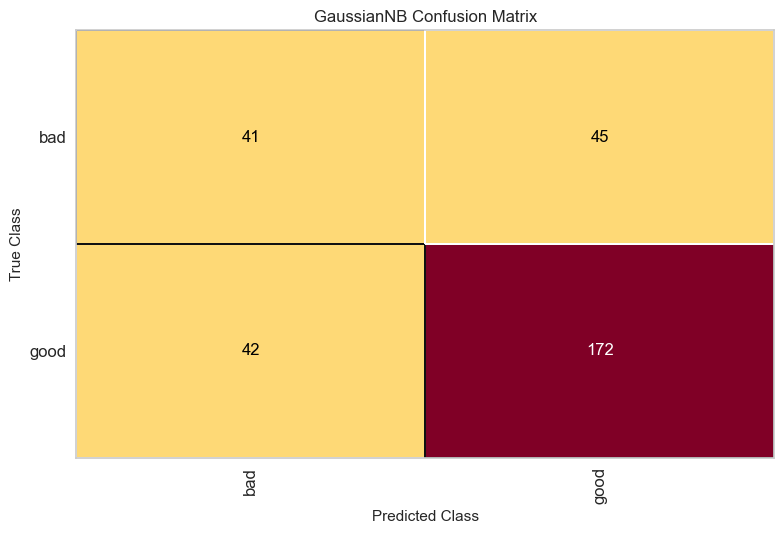

<Axes: title={'center': 'GaussianNB Confusion Matrix'}, xlabel='Predicted Class', ylabel='True Class'>

In [28]:
#Visualizacao da matriz de confusao usando a bibliotexa yellowbrick
v = ConfusionMatrix(GaussianNB())
v.fit(X_treinamento, y_treinamento)
v.score(X_teste, y_teste)
v.poof()

In [34]:
#Previsao com novo registro, transofrmando os atributos categoricos em numericos
novo_credito = pd.read_csv('NovoCredit.csv')
novo_credito.shape

(1, 20)

In [35]:
X_novo = novo_credito.iloc[:,0:20].values
X_novo[:,0] = labelencoder1.transform(X_novo[:,0])
X_novo[:,2] = labelencoder2.transform(X_novo[:,2])
X_novo[:,3] = labelencoder3.transform(X_novo[:,3])
X_novo[:,5] = labelencoder4.transform(X_novo[:,5])
X_novo[:,6] = labelencoder5.transform(X_novo[:,6])
X_novo[:,8] = labelencoder6.transform(X_novo[:,8])
X_novo[:,9] = labelencoder7.transform(X_novo[:,9])
X_novo[:,11] = labelencoder8.transform(X_novo[:,11])
X_novo[:,13] = labelencoder9.transform(X_novo[:,13])
X_novo[:,14] = labelencoder10.transform(X_novo[:,14])
X_novo[:,16] = labelencoder11.transform(X_novo[:,16])
X_novo[:,18] = labelencoder12.transform(X_novo[:,18])
X_novo[:,19] = labelencoder13.transform(X_novo[:,19])

In [36]:
naive_bayes.predict(X_novo)

array(['good'], dtype='<U4')